# Who Waits Longer in Buffalo? Measuring Fairness in 311 Response Times Across Neighborhoods
**CSE 487 Project Phase 1: Data Cleaning & Processing**
**Team CTRL-Freaks:** Jayda Johnson, Meena Kasina, Josh Hu

**Research question:** Are 311 response times fair across Buffalo's council districts and neighborhoods from 2020 to 2026?

### Data Sources
This notebook loads live, externally hosted data directly from the City of Buffalo Open Data Portal, so no data files are included in the submission.
- [311 Service Requests (July 2008 to May 2024)](https://data.buffalony.gov/Quality-of-Life/311-Service-Requests-July-2008-May-2024-/whkc-e5vr/about_data)
- [311 Service Requests (May 2024 to Present)](https://data.buffalony.gov/Quality-of-Life/311-Service-Requests-May-2024-Present-/3tj7-3tdz/about_data)

### Cleaning & Processing Pipeline
The operations run in this order because some steps depend on earlier ones:

| # | Operation | Why it runs here |
|---|---|---|
| 1 | Data Integration | Combines both datasets so every later step runs on one table |
| 2 | Removing Irrelevant Data | Trims rows and columns before any heavier processing |
| 3 | Data Type Conversion | Dates and coordinates must be real types before they can be checked |
| 4 | String Cleaning | Cleans text so later grouping and duplicate checks match correctly |
| 5 | Fixing Swapped & Placeholder Coordinates | Creates new missing values that Operation 6 then handles |
| 6 | Handling Missing Data | Deals with all missing values, including those from Operation 5 |
| 7 | Removing Duplicates | Uses the original request types, so it runs before they are grouped |
| 8 | Category Standardization | Groups request types into broader categories last |

A final set of checks at the end confirms each operation did what it was supposed to.

In [1]:
import os
import numpy as np
import pandas as pd

## Loading the Data
Both datasets are read straight from the City of Buffalo Open Data Portal as CSV files. `low_memory=False` tells pandas to read each column in one pass so it doesn't guess mixed data types.

*Note: the older dataset is large (about 1.1 million rows), so this cell can take a minute or two to run.*

In [2]:
# URLs to the online data files
old_url = "https://data.buffalony.gov/api/views/whkc-e5vr/rows.csv?accessType=DOWNLOAD"
new_url = "https://data.buffalony.gov/api/views/3tj7-3tdz/rows.csv?accessType=DOWNLOAD"

# Load both datasets directly from the portal
oldDf = pd.read_csv(old_url, low_memory=False)
newDf = pd.read_csv(new_url, low_memory=False)

print("July 2008-May 2024: ",oldDf.shape)
print("May 2024-Present: ",newDf.shape)

July 2008-May 2024:  (1129274, 34)
May 2024-Present:  (206914, 28)


## Operation 1: Data Integration
**What:** Merge the two 311 datasets into one dataset covering January 2020 to present.

**Why:** Our time range is split across two files, and the old and new city systems store the same information under different column names.

**How:**
1. Filter the July 2008 to May 2024 data to requests opened on or after January 1, 2020
2. Rename the newer dataset's columns to match the older dataset (ex: `Created Date` → `Open Date`, `CaseNumber` → `Case Reference`)
3. Keep only the columns both datasets share, plus `Duplicate Request` (new data) and `Council District 2011` (old data), which later operations need
4. Add a `Source` column so each row can be traced back to its original file
5. Stack the two datasets with `pd.concat()`

In [3]:
# Step 1: Filter oldDf to January 2020 and later
# We parse "Open Date" into a temporary datetime Series just to filter.
# We do NOT overwrite the original column, since converting date
# columns is its own cleaning step (Data Type Conversion).
old_open_dates = pd.to_datetime(oldDf["Open Date"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
oldDf = oldDf[old_open_dates >= "2020-01-01"].copy()
print("oldDf after filtering to 2020+:", oldDf.shape)

oldDf after filtering to 2020+: (362538, 34)


In [4]:
# Step 2: Rename newDf's columns to match oldDf's names
# Left side = newDf's name, right side = oldDf's name for the same info.
column_mapping = {
    "Created Date": "Open Date",
    "CaseNumber": "Case Reference",
    "Department": "Subject",
    "PropertyID": "Property ID",
    "Assessed Number": "Address Number",
    "AssessedStreet": "Address Line 1",
    "Zip": "Zipcode",
    "PoliceDistrict": "Police District",
    "PlanningNeighborhood": "Neighborhood",
}
newDf = newDf.rename(columns=column_mapping)

In [5]:
# Step 3: Keep only the columns both datasets share
# Columns that only exist in one file would be empty (NaN) for the
# other file's rows after stacking, so we keep the shared ones only.
shared_columns = [
    "Case Reference",
    "Open Date",
    "Closed Date",
    "Status",
    "Subject",
    "Type",
    "Address Number",
    "Address Line 1",
    "City",
    "State",
    "Zipcode",
    "Property ID",
    "Latitude",
    "Longitude",
    "Location",
    "Council District",
    "Police District",
    "Census Tract",
    "Census Block Group",
    "Census Block",
    "Neighborhood",
]
# The old data also has "Council District 2011", which Op 4 uses to fill in
# missing council districts, so we keep it too (new rows will be NaN).
oldDf = oldDf[shared_columns + ["Council District 2011"]]

# newDf also has a "Duplicate Request" flag that we need later for
# Duplicate Removal, so we keep it alongside the shared columns.
newDf = newDf[shared_columns + ["Duplicate Request"]]

In [6]:
# Step 4: Tag each row with the dataset it came from
# This makes it easy to trace any issue back to its original file.
oldDf = oldDf.assign(Source="July 2008-May 2024 dataset")
newDf = newDf.assign(Source="May 2024-Present dataset")

In [7]:
# Step 5: Stack the two datasets into one
# pd.concat places newDf's rows underneath oldDf's rows.
# ignore_index=True renumbers the rows from 0 to the end.
# oldDf rows will show NaN for "Duplicate Request" since the old
# dataset did not track duplicates.
merged_df = pd.concat([oldDf, newDf], ignore_index=True)
print("Merged Dataset:", merged_df.shape)

Merged Dataset: (569452, 24)


## Operation 2: Removing Irrelevant Data
**What:** Remove rows and columns that don't help answer our research question.

**Why:** Test entries aren't real requests, and extra columns add clutter without adding value.

**How:**
- **Rows:** Drop the 4 test entries where the department (`Subject`) is `"Test"`. (The 2020+ date filter already happened in Operation 1.)
- **Columns:** Drop columns that repeat other information or aren't needed:
  - `Location`: same information as `Latitude` and `Longitude` in a different format
  - `City`, `State`: every row is Buffalo, NY
  - `Census Block Group`, `Census Block`: more specific than our analysis needs
  - `Property ID`: parcel IDs aren't needed for our question

**Kept on purpose:** `Census Tract` (so we can later compare requests per resident using Census population data), `Council District 2011` (used in Operation 6), and `Duplicate Request` (used in Operation 7).

In [8]:
# Start cleaning from the merged dataset created in Operation 1
df = merged_df.copy()
print("Shape before:", df.shape)

# Double-check that the 2020+ filter from Operation 1 worked
openDates = pd.to_datetime(df["Open Date"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
print("Earliest date:", openDates.min())
print("Latest date:", openDates.max())

Shape before: (569452, 24)


Earliest date: 2020-01-01 10:28:00
Latest date: 2026-10-17 05:52:00


In [9]:
# Remove test entries, which aren't real requests
testRows = df["Subject"] == "Test"
print("Test rows removed:", testRows.sum())
df = df[~testRows]

# Drop columns that repeat other information or aren't needed
dropCols = ["Location", "Census Block Group", "Census Block", "City", "State", "Property ID"]
df = df.drop(columns=dropCols)

print("Shape after:", df.shape)
print(list(df.columns))

Test rows removed: 4
Shape after: (569448, 18)
['Case Reference', 'Open Date', 'Closed Date', 'Status', 'Subject', 'Type', 'Address Number', 'Address Line 1', 'Zipcode', 'Latitude', 'Longitude', 'Council District', 'Police District', 'Census Tract', 'Neighborhood', 'Council District 2011', 'Source', 'Duplicate Request']


## Operation 3: Data Type Conversion
**What:** Convert columns to their correct data types.

**Why:** Dates stored as text can't be used to calculate response times, which is the core of our project.

**How:**
- `Open Date`, `Closed Date` → datetime (both files use the format `09/03/2026 02:15:00 PM`)
- `Latitude`, `Longitude` → numeric
- `Duplicate Request` → True/False (old rows are blank because the old system didn't have this flag, so they become False)
- `Census Tract` → one consistent 6-digit code. The new data already uses codes like `002400`, but the old data writes the same tract as a decimal like `24` or `16.02`. Multiplying old values by 100 and padding with zeros gives the matching code (`24` → `002400`, `16.02` → `001602`). Anything that still isn't 6 digits (`UNKNOWN` or broken codes) becomes missing.

`errors="coerce"` turns anything that can't be converted into a missing value instead of crashing, and we count how many that happened to.

In [10]:
print("Data types before conversion:")
print(df.dtypes)

Data types before conversion:
Case Reference            object
Open Date                 object
Closed Date               object
Status                    object
Subject                   object
Type                      object
Address Number            object
Address Line 1            object
Zipcode                   object
Latitude                 float64
Longitude                float64
Council District          object
Police District           object
Census Tract              object
Neighborhood              object
Council District 2011     object
Source                    object
Duplicate Request         object
dtype: object


In [11]:
dateFormat = "%m/%d/%Y %I:%M:%S %p"
df["Open Date"] = pd.to_datetime(df["Open Date"], format=dateFormat, errors="coerce")
df["Closed Date"] = pd.to_datetime(df["Closed Date"], format=dateFormat, errors="coerce")
df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce")
df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce")

# Old rows are blank here (no duplicate flag in the old system), so they become False
df["Duplicate Request"] = df["Duplicate Request"].astype(str).str.lower() == "true"

print("Data types after conversion:")
print(df.dtypes)

# Open Date should have 0 failures. A missing Closed Date means the case is still open, not a failed conversion
print("Open Date that failed to parse:", df["Open Date"].isna().sum())
print("Closed Date empty (open cases):", df["Closed Date"].isna().sum())

Data types after conversion:
Case Reference                   object
Open Date                datetime64[ns]
Closed Date              datetime64[ns]
Status                           object
Subject                          object
Type                             object
Address Number                   object
Address Line 1                   object
Zipcode                          object
Latitude                        float64
Longitude                       float64
Council District                 object
Police District                  object
Census Tract                     object
Neighborhood                     object
Council District 2011            object
Source                           object
Duplicate Request                  bool
dtype: object
Open Date that failed to parse: 0
Closed Date empty (open cases): 17328


In [12]:
# Census tract is written two ways: old = decimal like 24 or 16.02, new = 6-digit text like "002400"
fromOld = df["Source"] == "July 2008-May 2024 dataset"
tract = df["Census Tract"].astype(str).str.strip()

# Old codes: multiply by 100 and pad with zeros to match (24 -> 002400, 16.02 -> 001602)
oldNum = pd.to_numeric(tract[fromOld], errors="coerce") * 100
tract[fromOld] = oldNum.round().apply(lambda x: f"{int(x):06d}" if pd.notna(x) else np.nan)

# Anything that still isn't 6 digits is invalid (UNKNOWN or broken 4-5 digit codes in the new data)
badTract = ~tract.str.fullmatch(r"\d{6}", na=False)
print("Invalid tract codes set to missing:", badTract.sum())
tract[badTract] = np.nan
df["Census Tract"] = tract

print("Distinct tracts:", df["Census Tract"].nunique())
print(df["Census Tract"].value_counts().head())

Invalid tract codes set to missing: 23826
Distinct tracts: 126
Census Tract
000200    15903
002400    13486
004300    11552
003700    11148
004500    11012
Name: count, dtype: int64


## Operation 4: String Cleaning
**What:** Clean up inconsistent text formatting and spelling in the `Type` and `Subject` (department) columns.

**Why:** The same department appears under different names (ex: `Parking` and `Dept of Parking`), which would split its requests into separate groups.

**How:**
- Remove the `(Req_Serv)` suffix from request types, since every row is already a service request
- Combine department name variants into one consistent name
- Label missing departments as `Unknown`

In [13]:
# Remove the "(Req_Serv)" suffix from request types, since every row is already a service request
df['Type'] = df['Type'].str.replace(' (Req_Serv)', '', regex=False)

In [14]:
# Combine department name variants into one consistent name
updated_request_map = {"Mayor's Office": "Office of the Mayor",
                       "Parking" : "Parking Department",
                       "Dept of Parking" : "Parking Department",
                       "Dept of Public Works": "Public Works, Parks, & Streets Department",
                       "Public Works, Parks & Streets" : "Public Works, Parks, & Streets Department",
                       "Community Services & Rec. Program.": "Community Service & Recreational Programming",
                       "Community Services & Recreational Programming": "Community Service & Recreational Programming",
                       "DPIS" : "Permit & Inspection Services",
                       "Dept of Law" : "Law Department"
}
df['Subject'] = df['Subject'].replace(updated_request_map)
# Label missing departments as Unknown
df['Subject'] = df['Subject'].fillna('Unknown')

## Operation 5: Fixing Swapped & Placeholder Coordinates
**What:** Correct invalid values in `Latitude` and `Longitude`.

**Why:** Bad coordinates would place requests in the wrong location on maps and in any location-based analysis.

**How:**
1. **Swapped coordinates (new data):** About 10,000 rows have latitude around -78.8 and longitude around 42.9. Buffalo's latitude is positive (about 42.9), so any row with a negative latitude was flipped, and we swap it back.
2. **Placeholder coordinates (old data):** About 85% of old rows (nearly all of 2020 to 2023) are stored at exactly (43.0, -79.0). This isn't a real location; it's a default the old system filled in. Leaving it would stack 300,000+ requests on one fake point, so we set these to missing. These rows still have a council district and neighborhood, so they remain usable.
3. **Boundary check:** Any remaining coordinates outside Buffalo (latitude 42.82 to 42.97, longitude -78.92 to -78.79, based on the range of real coordinates) are set to missing.

*This runs before Operation 6 because it creates new missing values that Operation 6 then handles.*

In [15]:
# Buffalo's latitude is positive (about 42.9), so a negative latitude means lat and lon were swapped
swapped = df["Latitude"] < 0
print("Rows with swapped coordinates:", swapped.sum())
print(df.loc[swapped, "Source"].value_counts())

tempLat = df.loc[swapped, "Latitude"]
df.loc[swapped, "Latitude"] = df.loc[swapped, "Longitude"]
df.loc[swapped, "Longitude"] = tempLat

print("Rows with negative latitude after fix:", (df["Latitude"] < 0).sum())

Rows with swapped coordinates: 10126
Source
May 2024-Present dataset    10126
Name: count, dtype: int64
Rows with negative latitude after fix: 0


In [16]:
# (43.0, -79.0) appears 300,000+ times. It's a default placeholder, not a real location
print(df["Latitude"].value_counts().head(3))

placeholder = (df["Latitude"] == 43) & (df["Longitude"] == -79)
print("Placeholder coordinate rows:", placeholder.sum())
print(df.loc[placeholder, "Open Date"].dt.year.value_counts().sort_index())

df.loc[placeholder, "Latitude"] = np.nan
df.loc[placeholder, "Longitude"] = np.nan

Latitude
43.000000    309526
42.913366       404
42.912594       307
Name: count, dtype: int64
Placeholder coordinate rows: 309526
Open Date
2020    67441
2021    72826
2022    97446
2023    71813
Name: count, dtype: int64


In [17]:
# Any coordinates outside Buffalo's boundaries are treated as invalid
inBuffalo = df["Latitude"].between(42.82, 42.97) & df["Longitude"].between(-78.92, -78.79)
outside = df["Latitude"].notna() & ~inBuffalo
print("Coordinates outside Buffalo:", outside.sum())

df.loc[outside, "Latitude"] = np.nan
df.loc[outside, "Longitude"] = np.nan

print("Rows with valid coordinates:", df["Latitude"].notna().sum(), "/", len(df))

Coordinates outside Buffalo: 0
Rows with valid coordinates: 239917 / 569448


## Operation 6: Handling Missing Data
**What:** Find all missing values and decide how to handle each column.

**Why:** Both city systems write the text `"UNKNOWN"` (and sometimes `"UnAssigned"`) instead of leaving cells blank, so pandas doesn't recognize them as missing and `isna()` undercounts them.

**How:**
1. Convert `"UNKNOWN"`, `"UnAssigned"`, and empty text to true missing values, then compare missing counts before and after
2. **`Council District`:** The old system left this blank for most of 2020 to 2021. `Council District 2011` is filled for most of those rows, so we use it to fill the gaps and then drop it. *Limitation: 2011 district lines don't perfectly match current ones, so a small share of filled-in districts may be off.*
3. **Rows still missing `Council District`:** Dropped, since comparing districts is the point of our project
4. **Missing `Closed Date`:** These are still-open cases, not bad data. We keep them and flag them with a new `isOpen` column so response time analysis can skip them
5. **`Latitude`, `Longitude`, `Zipcode`, `Neighborhood`, `Police District`, address columns:** Left as missing, since not every analysis needs them and dropping those rows would throw away useful data

In [18]:
# "UNKNOWN" is a missing value that isna() can't detect, so convert it to NaN
missingBefore = df.isna().sum()
unknownBefore = (df == "UNKNOWN").sum() + (df == "UnAssigned").sum()

df = df.replace(["UNKNOWN", "UnAssigned", ""], np.nan)

missingTable = pd.DataFrame({
    "Missing before": missingBefore,
    "UNKNOWN text": unknownBefore,
    "Missing after": df.isna().sum(),
    "% missing": (df.isna().sum() / len(df) * 100).round(2)})
missingTable

,Missing before,UNKNOWN text,Missing after,% missing
Case Reference,0,0,0,0.00
Open Date,0,0,0,0.00
Closed Date,17328,0,17328,3.04
Status,0,0,0,0.00
Subject,0,0,0,0.00
Type,0,0,0,0.00
Address Number,22465,0,22465,3.95
Address Line 1,3828,0,3828,0.67
Zipcode,10769,19753,30522,5.36
Latitude,329531,0,329531,57.87


In [19]:
# Fill missing council districts using the 2011 district column, then drop it
print("Council District missing before:", df["Council District"].isna().sum())
df["Council District"] = df["Council District"].fillna(df["Council District 2011"])
print("Council District missing after fill:", df["Council District"].isna().sum())

df = df.drop(columns=["Council District 2011"])

Council District missing before: 160171
Council District missing after fill: 22458


In [20]:
# Rows with no council district can't be compared, so they are dropped
noDistrict = df["Council District"].isna()
print("Rows with no district dropped:", noDistrict.sum())
df = df[~noDistrict]

# Keep open cases, but flag them so response time analysis can skip them
df["isOpen"] = df["Closed Date"].isna()
print("Open cases kept:", df["isOpen"].sum())
print("Rows remaining:", len(df))

Rows with no district dropped: 22458
Open cases kept: 14581
Rows remaining: 546990


## Operation 7: Removing Duplicates
**What:** Remove repeat reports of the same issue.

**Why:** Duplicates inflate request counts for some areas, which would skew comparisons between districts.

**How:**
1. Check for exact duplicate rows and repeated case IDs (both are 0, and the two datasets' date ranges don't overlap)
2. Remove requests the new system flagged itself as duplicates (`Duplicate Request = True`)
3. Remove near-duplicates: same request type, same address, same day, keeping the earliest report. Rows with no street address are skipped, since we can't confirm they're the same location.

*This runs before Operation 8 so near-duplicates are matched on the original, specific request types.*

In [21]:
# Check for exact duplicate rows and repeated case IDs
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate case IDs:", df["Case Reference"].duplicated().sum())

Exact duplicate rows: 0
Duplicate case IDs: 0


In [22]:
# Remove requests the city's new system flagged as duplicates
flagged = df["Duplicate Request"] == True
print("Flagged duplicates removed:", flagged.sum())
df = df[~flagged]
df = df.drop(columns=["Duplicate Request"])

Flagged duplicates removed: 4872


In [23]:
# Same type, same address, same day = the same issue reported more than once
# Sort by time first so keep="first" keeps the earliest report
df = df.sort_values("Open Date")
df["createdDay"] = df["Open Date"].dt.date

nearDupes = df.duplicated(subset=["Type", "Address Number", "Address Line 1", "createdDay"], keep="first")
# Skip rows with no street, since we can't confirm they're the same location
nearDupes = nearDupes & df["Address Line 1"].notna()

print("Near-duplicates removed:", nearDupes.sum())
print(df.loc[nearDupes, "Source"].value_counts())

df = df[~nearDupes]
df = df.drop(columns=["createdDay"])
df = df.reset_index(drop=True)
print("Rows remaining:", len(df))

Near-duplicates removed: 13837
Source
July 2008-May 2024 dataset    10861
May 2024-Present dataset       2976
Name: count, dtype: int64
Rows remaining: 528281


## Operation 8: Category Standardization
**What:** Group 300+ specific request types into broader categories.

**Why:** Many request types describe the same issue under different names (ex: `Pot Hole`, `Pothole Issue`, and `Other Hole in Road`), which makes comparisons by type unreliable.

**How:** Each request type is mapped into one of 24 categories (ex: `Roads & Potholes`, `Snow Management`). Anything that doesn't match a category is labeled `Other`.

In [24]:
print("Unique request types before grouping:", df['Type'].nunique())

# Waste categories
totes_bins = ['Totes Audit', 'Totes Deliver', 'Tote Pickup', 'Totes Pickup',
              'Totes Replace', 'Totes Combo', 'Totes Abandon Pickup',
              'Totes Report of Removed Broken Tote', 'Special Even Totes',
              'Order Additional or Change Current Totes', 'Replacement Garbage Totes Request',
              'Recycling Tote Replace', 'Recycyling Tote Deliver', 'Recycling Tote Pickup',
              'Recycling Tote Abandon Pickup', 'Recycling Tote Combo', 'Recycling Tote Combo (Exchange Size)','Impact Bill Inquiry or Concern',
              'Special Event Totes']
regular_bulk_collection = [
    "Garbage Missed Pick Up", "Recycling Missed Pick Up", "Missed Pickup 2_Piece Large Trash",
    "Missed Pickup; 2 Piece Large Trash", "Missed Pickup; 3 Piece Large Trash",
    "Bulk Trash", "Bulk Trash Issue", "Scrap_It Curbside",
    "Senior or Disabled Citizen, TV Pickup Request",
    "Senior or Disabled Citizen, TV/Electronics Pickup Request", "Electronic Waste",
    "TV and Electronic Waste at Curb", "Fridge", "Fridge Removal", "Christmas Tree",
    "Christmas Tree Removal", "Leaves / Lawn Debris", "High Grass/Weeds",
    "Shopping Carts (Impact Team)", 'Trash Ordinance Violation','Rain Barrels'
]
illegal_dumping_debris = [
    "Excess Trash", "Illegal Dumping Curb", "Illegal Dumping PrivateProperty",
    "Illegal Dumping", "OSP Illegal Dumping", "QRT Illegal Dumping on Viaduct",
    "Illegal Dumping Private Property / Vacant Lot", "Great American Clean-Up",
    "Neighborhood CleanUp", "Neighborhood CleanUp Request",
    "Weather Emergency Trash Pick Up - 9/3/2026 Event", 'Illegal Dumping Street'
]

Unique request types before grouping: 308


In [25]:
# Streets, sidewalks, and roads
roads_and_potholes = [
    "Pot Hole", "Other Hole in Road", "Pothole Issue", "Paving", "Street Paving Request",
    "Cave In", "PW Ongoing Construction", "PW Ongoing Construction Issue",
    "PW Engineering", "Obscene PW Engineering", 'Engineering Operational', 'Damage from Street Worker',
    'CityHall_CityCourt Maintenance'
]
sidewalks_and_curbs = [
    "Sidewalks", "New Sidewalk/Ramp", "Sidewalk(s) Repair Request", "Sidewalk(s) Issue",
    "Curbs", "Curbs Replacement Request", "Curb - Metal Protruding",
    "Curb - Metal Protruding Issue", "Bike Rack", "Bike Rack Issue", "Bike Rack Request"
]
lighting_and_signals = [
    "Streetlights", "Streetlight(s) Issues", "Damaged Street Light Pole",
    "Damaged or Missing Street Light Pole", "Signal Out or Flashing", "Signal Issue DoT",
    "Signal Other Issue", "Signal Issue", "Signal Timing Issue City",
    "Signal Timing Issue in City of Buffalo"
]
traffic_and_lines = [
    "Pavement Marking Lines", "Pavement Marking Issue", "Buffalo Traffic Violations",
    "PVB School-Zone Camera Citations", "PW Traffic", "Obscene PW Traffic",
    "PW Neighborhood Traffic Calming", "Neighborhood Traffic Calming", "Speeding Issue(s)",
    "Bridge Issue", "Report Bridge Flooding", "Weather Event Damage to ROW Infrastructure",
    "Report Snow on Bridge or Viaduct", "Sweeper", "Sweeper Request", "Seweeper Issue", "ROW Bike Lane ; on-road or cycle tracks Issue"

]
obstructions_and_hazards = [
    "Basketball Hoop in RoW", "Basketball Hoop in Street", "Right of Way Issue",
    "Sign Hazards", "Sign Maintenance", "Sign Issue", "Down Wire(s)"]

In [26]:
# Forests and parks
tree_maintenance = [ "Tree Removal",
    "Tree Removal (Req_SERV)", "Tree Trimming Request", "Fallen Tree Blocking RoW",
    "Tree Other", "Fallen Tree Inspection", "Tree Removal Quality Issue (Req_serv)",
    "Tree Removal Challenge", "Stump Removal", "Tree Planting Request",
    "Tree Removal per Inspector", "Tree Pruning Request", "Tree Pruning Private Property",
    "Tree Planting Quality Issue", "Stump Removal Quality Issue",
    "Tree Trimming Quality Issue", "City Park Tree Issue",
    "Fallen Tree, split tree, hanging limb",
    "Fallen Tree Inspection on Private Property"
]
parks_and_recreation = [
    "City Parks", "City Parks Issue", "Parks City", "Olmsted Parks", "Olmsted Parks Issue",
    "Parks Olmsted", "RalphWilson Park Construction", "Ralph Wilson Park Issue",
    "Pools and Splashpads", "Pools and Splashpads Issue", "Recreation Center",
    "Recreation Center Issue", "Youth Bureau Issue", "Buffalo Place Park Issue",
    "Naval Park Issue", "Erie Basin Marina Issue",
    "Shoreline Trail, North Buffalo Rails to Trails, Jesse Kregal Pathway Issue",
    "Circles Medians Triangles Issues (Contractor)", "Obscene Parks City",
    "Obscene Parks Olmsted", "Parks Buildings Maintenance",
    "Tifft Nature Preserve Issue  (Buffalo Museum of Science)",
    "Pat Sole Park (Peace Bridge Authority)", "Ice Rink Issue"]

In [27]:
water_services = [
    "Water Issue", "Water_Billing_Meter", "Buffalo Water Service Request",
    "Buffalo Water Service Issue", "Buffalo Water Billing Request",
    "Buffalo Water Testing Request", "Water Tested"
]
drainage_and_sewers = [
    "Sewer", "Sewer Issue", "Report Flooding", "Street Flooding",
    "Basement Flooding", "Basement Flooding Issue", "PW Missing Manhole Cover"
]


In [28]:
# Housing and building code violations
violations_and_inspections = [
    "Housing Violations", "Open311 Housing", "Rental Registration",
    "Healthy Homes / PRI Inspection", "Housing or Building Violations(Exterior)",
    "Housing or Building Violations(Interior)", "Electrical Issue",
    "Electrical Violation (Interior)", "Electrical Violation (Exterior)",
    "Heating or A/C Issues(Exterior)", "Heating or A/C Issues(Interior)",
    "Property Issue(s)  (Quality of Life Issue)", "Short Term Rental Issue",
    "Zoning Board of Appeals Concern", 'Lead Paint Inspection', 'Building Maintenance', 'License Concern','Rodents',
    'Rodent Control Issue'
]
vacant_and_abandoned_properties = [
    "PW Vacant Lot", "Vacant Lot Cutting", "Inrem Real Estate", "Real Estate Issue",
    "Boarding request", "Board Up request", "Abandoned Property",
    "BPD Request Board Up/Cleanup Task, For Impact Team"
]
graffiti_and_obscenity = [
    "Open311 Graffiti", "Graffiti issue", "Graffiti Private Property",
    "Obscene City Property", "Obscene Parks City", "Obscene Private Property",
    "Obscene Other", "Graffiti, City Property or Right of Way (Impact Team)"
]

In [29]:
# Parking & vehicles
parking_enforcement_and_rules = [
    "Parking Issues", "General Parking Issue(s)",
    "Illegal Parking (Quality of Life Issue)", "Unlicensed Street Vendor",
    "Parking Pay Station Issue(s)", "Parking Mobile App Issue(s)",
    "Parking Single Meter Issue(s)"]
meters_and_apps = [
    "User Fee", "Public Works User Fee Issue", "PVB Mobile App Issue",
    "PVB Mobile App Ticket", "PVB Single Meter", "PVB Pay Station"
]
abandoned_vehicles = [
    "Abandoned Vehicles", "Abandoned Vehicle Inspection",
    "Privately Owned Property, Abandoned Vehicle", "Unregistered Vehicle",
    "Abandoned Vehicles (Parking Dept)",
    "Vehicle Immobilized in Street (Parking Dept)"]

In [30]:
# Public safety, fire, and animals
animal_and_wildlife_control = [
    "Animals", "Dead Animal Removal", "Dead Animal Removal Request",
    "Dog License Issue", "Dog Animal Control Issue", "Wildlife Control Issue",
    "Bees and Hornets Animal Control Issue", "Personal Wildlife Trap Report",
    "Pest", "Pest_Private Trap", "Chicken Coop", "Chicken Issue",
    "Dog Licensing Issue", "Livestock Issue"
]
nuisance_and_quality_of_life = [
    "Excessive Noise", "Noise Nuisance (Loud Music)", "Loitering", "Panhandling",
    "Homeless Concern (Quality of Life Issue)", "Juvenile / Youth Concern",
    "Quality of Life Issue", "Quality of Life Issue (Other)", "Good Neighbor",
    "Sneakers Hanging", "ATV and or Dirt Bike", "Unlicensed Business"
]
fire_safety_and_police = [
    "Fire", "BFD Fire Prevention", "Buffalo Fire Prevention Request",
    "General Fire Issue", "Police Issue", "Police Issue (Other)",
    "Public Safety Support - (BFD)"
]

In [31]:
# Winter/weather
snow_management = [
    "Street Snow Plowing Issue", "Street Snow Plowing", "Street Snow Plowing Request",
    "Street Salting", "Street Salting Issue", "Street Salting Request",
    "QRT Snow Removal", "Snow Removal", "Snow Removal Inspection",
    "Sidewalk Snow Removal Inspection", "Sidewalk Snow/Ice Removal Inspection",
    "Snow Removal Bus Stop/Shelter", "Damage from Snow Removal",
    "Vehicle Blocking Snow Plow", "Snow Removal Concern", "Snow-Bank Removal",
    "BFD Snow on Hydrant", "Buffalo Fire Department Snow on Hydrant"]

In [32]:
# Internal or administrative issues
administrative_and_records = [
    "FOIL Records EDPIS", "FOIL Records Citizens Services",
    "FOIL Records Board of Ethics", "City Clerk Issue", "General City Clerk Issue",
    "Taxation Issue", "Assessment Issue", "2020 Reassessment",
    "Compensation & Benefits", "New Americans Request"
]

internal_and_operations = [
    "BMHA Issue", "Pick and Pay", "Open311 APP Issues",
    "Report Technical Issue for Buff311 App", "Telecommunications",
    "General Impact Team Request", "Johnnie B Wiley Issue (BPS)", "Schools",
    "Save Our Streets Program", "Other Adjudication Issue",
    "Outer Harbor Parkway (Empire State Development Corp)", "CBO",
    "Fair Housing Issue", "FairHsg Other", "Security Deposit",
    "Union Ship Canal Issue (BUDC)", "DPIS Department Operational Complaint",
    "Obscene Schools", "DPIS Personnel Complaint"
]

In [33]:
# Map each category name to its list of request types
mapping = {"Totes & Bins" : totes_bins,
           "Regular & Bulk Collection":regular_bulk_collection,
           "Illegal Dumping & Debris" : illegal_dumping_debris,
           "Roads & Potholes" : roads_and_potholes,
           "Sidewalks & Curbs": sidewalks_and_curbs,
           "Lighting & Signals" : lighting_and_signals,
           "Traffic & Lines": traffic_and_lines,
           "Obstruction & Hazards": obstructions_and_hazards,
           "Tree Maintenance": tree_maintenance,
           "Parks & Recreation":parks_and_recreation,
           "Water Services": water_services,
           "Drainage & Sewers": drainage_and_sewers,
           "Violations & Inspections": violations_and_inspections,
           "Vacant & Abandoned Properties": vacant_and_abandoned_properties,
           "Graffiti & Obscenity": graffiti_and_obscenity,
           "Parking Enforcement & Rules": parking_enforcement_and_rules,
           "Meters & Apps": meters_and_apps,
           "Abandoned Vehicles": abandoned_vehicles,
           "Animal & Wildlife Control" : animal_and_wildlife_control,
           "Nuisance & Quality of Life": nuisance_and_quality_of_life,
           "Fire Safety & Police" : fire_safety_and_police,
           "Snow Management": snow_management,
           "Administrative & Records": administrative_and_records,
           "Internal & Operations" : internal_and_operations
           }

In [34]:
# Assign each request type to its category, or "Other" if it doesn't match any list
def assign_grouping(type_data):
  for group,lst in mapping.items():
    if type_data in lst:
      return group
  return "Other"
df['Type'] = df['Type'].apply(assign_grouping)

In [35]:
print("Unique request types after grouping:", df['Type'].nunique())
df['Type'].unique()

Unique request types after grouping: 25


array(['Parking Enforcement & Rules', 'Violations & Inspections',
       'Nuisance & Quality of Life', 'Illegal Dumping & Debris',
       'Roads & Potholes', 'Animal & Wildlife Control',
       'Vacant & Abandoned Properties', 'Regular & Bulk Collection',
       'Totes & Bins', 'Internal & Operations', 'Lighting & Signals',
       'Abandoned Vehicles', 'Obstruction & Hazards', 'Other',
       'Tree Maintenance', 'Water Services', 'Fire Safety & Police',
       'Meters & Apps', 'Traffic & Lines', 'Administrative & Records',
       'Parks & Recreation', 'Snow Management', 'Drainage & Sewers',
       'Sidewalks & Curbs', 'Graffiti & Obscenity'], dtype=object)

## Final Checks
These checks confirm each operation did what it was supposed to. If any check fails, the notebook stops with an error.

In [36]:
# Each check confirms one operation worked as intended
assert (df["Latitude"] < 0).sum() == 0
assert df["Latitude"].dropna().between(42.82, 42.97).all()
assert (df == "UNKNOWN").sum().sum() == 0
assert df["Council District"].isna().sum() == 0
assert str(df["Open Date"].dtype).startswith("datetime64")
assert str(df["Closed Date"].dtype).startswith("datetime64")
assert df["Case Reference"].duplicated().sum() == 0
assert (df["Census Tract"].dropna().str.len() == 6).all()

print("All checks passed!")
print("Final shape:", df.shape)
print(df["Source"].value_counts())

All checks passed!
Final shape: (528281, 17)
Source
July 2008-May 2024 dataset    331462
May 2024-Present dataset      196819
Name: count, dtype: int64


# Phase 2, Split A: How long do people wait?
Everything above is our Phase 1 notebook as submitted (minus the EDA and the optional save step, to keep runtime down). Phase 2 starts here.

# Shared Phase 2 Features
These features are the same in all three Phase 2 notebooks, so everyone's models run on identical data. **Don't change this cell in your own notebook.** If a change is needed, tell the team so we update all three.

| Feature | What it is |
|---|---|
| `resolutionDays` | Days from Open Date to Closed Date (missing for still-open cases) |
| `openYear`, `openMonth` | Year and month the request was opened |
| `season` | Winter, Spring, Summer, or Fall |
| `afterSwitch` | True if opened on or after May 11, 2024, when Buffalo switched 311 systems |
| `isSlow` | True if a closed request took longer than the median for its request category (missing for open cases) |

In [37]:
# Resolution time in days (still-open cases stay missing)
df["resolutionDays"] = (df["Closed Date"] - df["Open Date"]).dt.total_seconds() / 86400

# Time features
df["openYear"] = df["Open Date"].dt.year
df["openMonth"] = df["Open Date"].dt.month
seasons = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}
df["season"] = df["openMonth"].map(seasons)

# Before vs. after Buffalo's 311 system switch in May 2024
df["afterSwitch"] = df["Open Date"] >= "2024-05-11"

# Slow = took longer than the median for its request category (closed cases only),
# so a request is only called slow compared to similar requests
typeMedian = df.groupby("Type")["resolutionDays"].transform("median")
df["isSlow"] = (df["resolutionDays"] > typeMedian).where(df["resolutionDays"].notna())

print("Closed cases with a resolution time:", df["resolutionDays"].notna().sum())
print("Median resolution time (days):", round(df["resolutionDays"].median(), 2))
print("Share of closed requests labeled slow:", round(df["isSlow"].mean(), 3))
df[["resolutionDays", "openYear", "openMonth", "season", "afterSwitch", "isSlow"]].head()

Closed cases with a resolution time: 514337
Median resolution time (days): 3.99
Share of closed requests labeled slow: 0.5


,resolutionDays,openYear,openMonth,season,afterSwitch,isSlow
0,1.035417,2020,1,Winter,False,True
1,1.013194,2020,1,Winter,False,True
2,2.063889,2020,1,Winter,False,False
3,0.901389,2020,1,Winter,False,False
4,1.093750,2020,1,Winter,False,True


# Algorithm 1: Linear Regression
**Question it answers:** How many days does a request take based on district, request type, and month? (Q1)

In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# only closed cases, open ones dont have a resolution time yet
lrDf = df[df["resolutionDays"].notna()].copy()

# one hot the catagories so the model can use them. drop first means one district, DELAWARE since its first
# alphabeticaly, is the baseline and every other district gets compared to it
X = pd.get_dummies(lrDf[["Council District", "Type", "openMonth"]].astype(str), drop_first=True)
# the after switch flag is in here so the 2024 system change doesnt get blamed on a distrcit
X["afterSwitch"] = lrDf["afterSwitch"].astype(int)
X = X.astype(float)
y = lrDf["resolutionDays"]

xTrain, xTest, yTrain, yTest = train_test_split(X, y, test_size=0.2, random_state=42)
print("train rows:", len(xTrain), " test rows:", len(xTest), " features:", X.shape[1])

train rows: 411469  test rows: 102868  features: 44


In [39]:
# waits are super lopsided, the middle is about 4 days but some take over 1000, so i tried 2 versions
# version 1 predicts the raw days, version 2 predicts the log of the days and then undos the log after
rawModel = LinearRegression().fit(xTrain, yTrain)
rawPred = rawModel.predict(xTest).clip(min=0)  # negative days makes no sense

logModel = LinearRegression().fit(xTrain, np.log1p(yTrain))
logPred = np.expm1(logModel.predict(xTest))

# the baseline just guesses the median every time, both models need to beat this
basePred = np.full(len(yTest), yTrain.median())

results = []
for name, pred in [("baseline (always median)", basePred), ("v1 raw days", rawPred), ("v2 log days", logPred)]:
    results.append({
        "model": name,
        "R2 (days)": r2_score(yTest, pred),
        "R2 (log days)": r2_score(np.log1p(yTest), np.log1p(pred)),
        "MAE (days)": mean_absolute_error(yTest, pred),
        "RMSE (days)": np.sqrt(mean_squared_error(yTest, pred))})
results = pd.DataFrame(results).round(3)
results

,model,R2 (days),R2 (log days),MAE (days),RMSE (days)
0,baseline (always median),-0.058,-0.012,13.562,46.551
1,v1 raw days,0.121,-0.143,15.535,42.435
2,v2 log days,0.028,0.290,12.295,44.616


In [40]:
# which feature group actualy explains the wait? fit the log model on one group at a time
# and see how much of the wait each one explains by itself
groups = {"district only": "Council District_", "type only": "Type_", "month only": "openMonth_"}
for name, prefix in groups.items():
    cols = []
    for c in X.columns:
        if c.startswith(prefix):
            cols.append(c)
    m = LinearRegression().fit(xTrain[cols], np.log1p(yTrain))
    print(name, "R2 (log):", round(r2_score(np.log1p(yTest), m.predict(xTest[cols])), 3))
print("all together R2 (log):", round(r2_score(np.log1p(yTest), np.log1p(logPred)), 3))

district only R2 (log): 0.002
type only R2 (log): 0.277
month only R2 (log): 0.007
all together R2 (log): 0.29


SOUTH                   -5.8
NIAGARA                 -4.1
UNIVERSITY              -2.7
MASTEN                  -2.1
DELAWARE (reference)     0.0
LOVEJOY                  0.3
ELLICOTT                 1.7
FILLMORE                 2.3
NORTH                   13.5
dtype: float64


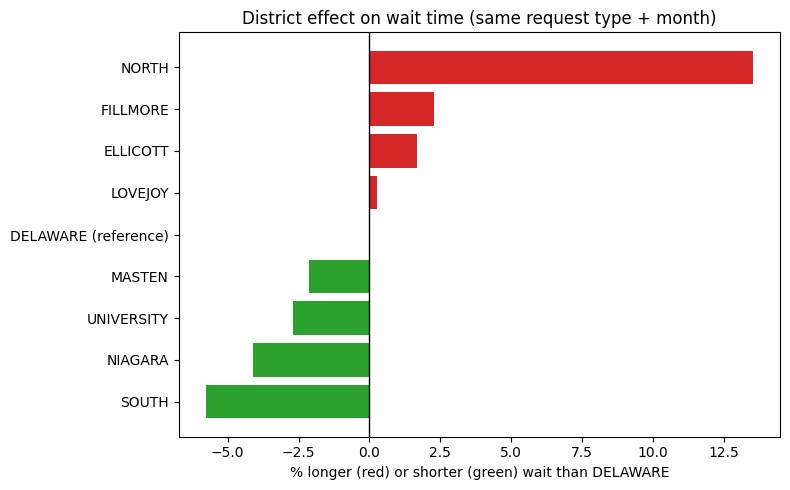

In [41]:
# because the target is a log, each district coefficent turns into a percent, how much longer or shorter
# that district waits compared to DELAWARE for the same request type and month. this is the fairness number we care about
coefs = pd.Series(logModel.coef_, index=X.columns)
distPct = (np.exp(coefs[coefs.index.str.startswith("Council District_")]) - 1) * 100
distPct.index = distPct.index.str.replace("Council District_", "")
distPct["DELAWARE (reference)"] = 0
distPct = distPct.sort_values()
print(distPct.round(1))

# red means it waits longer, green means it waits shorter
colors = []
for v in distPct:
    if v > 0:
        colors.append("tab:red")
    else:
        colors.append("tab:green")

plt.figure(figsize=(8, 5))
plt.barh(distPct.index, distPct.values, color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("% longer (red) or shorter (green) wait than DELAWARE")
plt.title("District effect on wait time (same request type + month)")
plt.tight_layout()
plt.show()

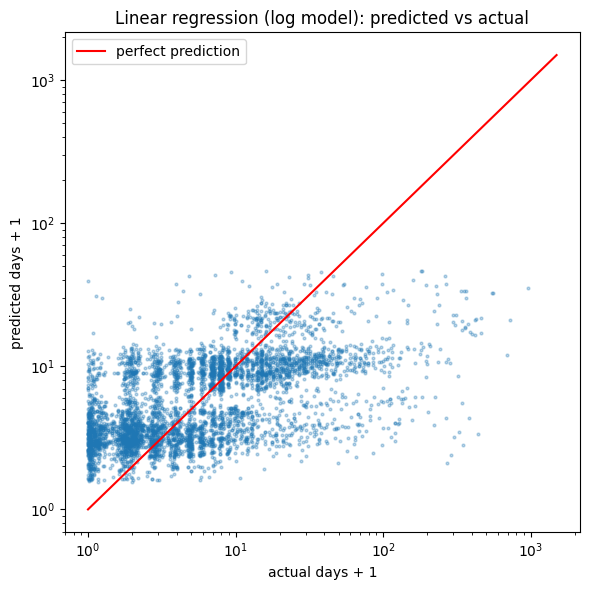

In [42]:
# predicted against actual for a random 5000 test rows, using log axes because of the huge spread
np.random.seed(42)
sample = np.random.choice(len(yTest), 5000, replace=False)
plt.figure(figsize=(6, 6))
plt.scatter(yTest.values[sample] + 1, logPred[sample] + 1, s=4, alpha=0.3)
plt.plot([1, 1500], [1, 1500], color="red", label="perfect prediction")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("actual days + 1")
plt.ylabel("predicted days + 1")
plt.title("Linear regression (log model): predicted vs actual")
plt.legend()
plt.tight_layout()
plt.show()

### Linear Regression Write-up
- **Why we chose it:** we wanted an actual number for "how many extra days does a district wait" after taking out request type and month. linear regression gives one coefficient per district so its easy to read, and its the simplist model to start w for Q1
- **Tuning / training:** closed cases only (514k), one-hot district / type / month + the afterSwitch flag, 80/20 train test split (random_state 42). waits r super skewed (median aprox 4 days, max aprox 1400) so i tryed raw days vs log(days + 1). the log version won on MAE (12.3 vs 15.5 days) and R2 on the log scale (0.29). also fit each feature group by itself to see which one acutally matters
- **Metrics:** log model: R2 0.29 (log scale), MAE 12.3 days vs 13.6 for the always-guess-the-median baseline. the raw model gets a higher R2 in days (0.12) bc it chases the huge outliers, but its MAE is worse then the baseline. R2 is low overall, which is kinda expeted since we dont have stuff like crew availablity or how bad the issue actually is
- **What it tells us:** request type explains almost all of it (type alone R2 0.28, district alone 0.002). after controlling for type + month, districts r all within aprox -6% to +14% of each other. NORTH waits aprox 14% longer then DELAWARE for the same kind of request, SOUTH aprox 6% shorter. UNIVERSITY has the slowest raw median but thats mostly bc of the kind of requets it gets, not the district itself. limitation: 2020-21 districts were filled from the 2011 district lines

# Algorithm 2: MapReduce
**Question it answers:** What is the median wait for each district each year, and did the gaps get better or worse? (Q1, Q3)

In [43]:
import time

# only closed cases, each row is just the district, the year and the days it took
mrDf = df[df["resolutionDays"].notna()]
rows = list(zip(mrDf["Council District"], mrDf["openYear"], mrDf["resolutionDays"]))

# split the data into 4 chunks, pretending each chunk lives on a diffrent machine
def splitIntoChunks(data, numChunks):
    chunkSize = len(data) // numChunks + 1
    chunks = []
    for i in range(0, len(data), chunkSize):
        chunks.append(data[i:i + chunkSize])
    return chunks

chunks = splitIntoChunks(rows, 4)
print("rows:", len(rows))
for c in chunks:
    print("chunk size:", len(c))

rows: 514337
chunk size: 128585
chunk size: 128585
chunk size: 128585
chunk size: 128582


In [44]:
# MAP: each machine turns every row into a key and a value. the key is the district and year, the value is the days
# it doesnt care what the other machines have
def mapper(chunk):
    out = []
    for district, year, days in chunk:
        out.append(((district, year), days))
    return out

# SHUFFLE: colect every value with the same key into one list, no matter which machine it came from
# hadoop does this part for you, here i just use a dictionary
def shuffle(mappedChunks):
    groups = {}
    for mapped in mappedChunks:
        for key, value in mapped:
            if key not in groups:
                groups[key] = []
            groups[key].append(value)
    return groups

# REDUCE: one key at a time, sort the days and grab the middle one, which is the median
# median not mean because a few 1000 day cases would drag the mean way up
def reducer(key, values):
    values = sorted(values)
    n = len(values)
    mid = n // 2
    if n % 2 == 1:
        median = values[mid]
    else:
        median = (values[mid - 1] + values[mid]) / 2
    return key[0], key[1], median, n

start = time.time()

mapped = []
for c in chunks:
    mapped.append(mapper(c))

grouped = shuffle(mapped)

reduced = []
for key in grouped:
    reduced.append(reducer(key, grouped[key]))
print("keys (district x year):", len(reduced), " time:", round(time.time() - start, 2), "sec")

mrResult = pd.DataFrame(reduced, columns=["district", "year", "medianDays", "count"])
mrResult.head()

keys (district x year): 63  time: 0.22 sec


,district,year,medianDays,count
0,LOVEJOY,2020,3.172569,9392
1,MASTEN,2020,3.925694,8212
2,NORTH,2020,3.719444,6496
3,NIAGARA,2020,3.974653,6288
4,DELAWARE,2020,3.057639,6187


In [45]:
# double check my mapreduce gets the exact same anwser as pandas groupby
check = df[df["resolutionDays"].notna()].groupby(["Council District", "openYear"])["resolutionDays"].median()
mine = mrResult.set_index(["district", "year"])["medianDays"].sort_index()
print("matches pandas:", np.allclose(mine.values, check.sort_index().values))

matches pandas: True


In [46]:
# table of the median wait in days for every district and year
medTable = mrResult.pivot(index="district", columns="year", values="medianDays").round(2)

# carefull, recent years still have slow cases that arent closed yet, so their medians look faster
# then they really are. showing the percent still open so we know how much to trust each year
openShare = (df.groupby("openYear")["isOpen"].mean() * 100).round(1)
print("% of requests still open, by year:")
print(openShare.to_string())
medTable

% of requests still open, by year:
openYear
2020    0.0
2021    1.3
2022    0.3
2023    1.3
2024    5.8
2025    1.9
2026    8.4


year,2020,2021,2022,2023,2024,2025,2026
district,,,,,,,
DELAWARE,3.06,3.51,3.93,3.81,4.56,4.18,4.11
ELLICOTT,3.09,3.85,4.11,4.11,4.15,3.15,2.97
FILLMORE,3.03,3.96,3.93,3.62,4.29,4.72,3.03
LOVEJOY,3.17,4.84,4.13,3.93,5.18,4.83,3.00
MASTEN,3.93,4.19,4.69,4.65,4.59,3.22,2.82
NIAGARA,3.97,3.85,3.79,3.83,3.86,3.24,2.43
NORTH,3.72,4.00,4.42,4.37,5.22,4.63,4.12
SOUTH,3.97,4.53,4.85,3.88,4.20,4.72,3.77
UNIVERSITY,3.65,4.09,4.94,4.83,5.81,5.01,3.99


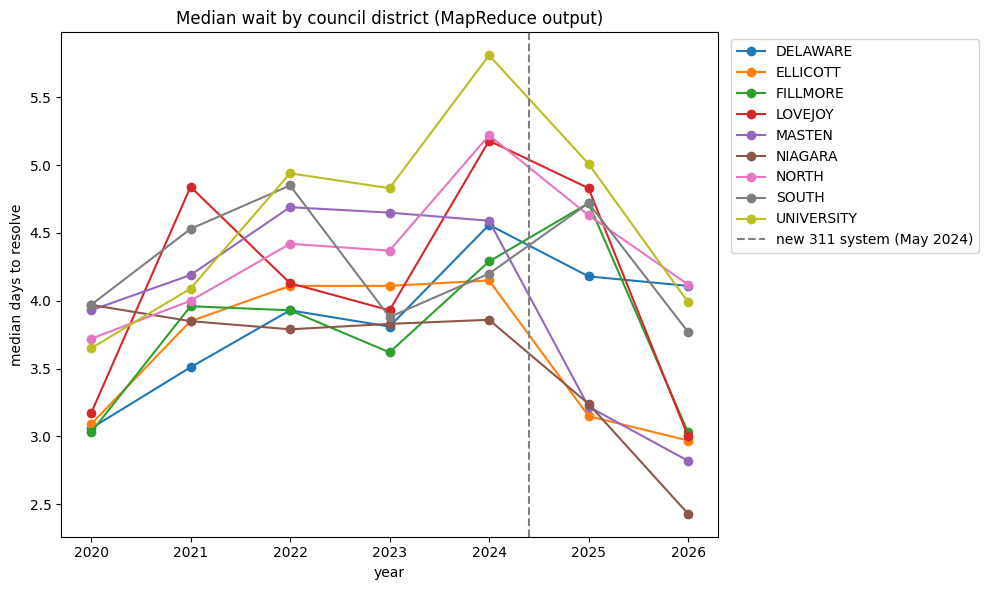

In [47]:
plt.figure(figsize=(10, 6))
for district in medTable.index:
    plt.plot(medTable.columns, medTable.loc[district], marker="o", label=district)
plt.axvline(2024.4, color="gray", linestyle="--", label="new 311 system (May 2024)")
plt.xlabel("year")
plt.ylabel("median days to resolve")
plt.title("Median wait by council district (MapReduce output)")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

         slowest  slowestDays   fastest  fastestDays  gapDays
year                                                         
2020     NIAGARA         3.97  FILLMORE         3.03     0.94
2021     LOVEJOY         4.84  DELAWARE         3.51     1.33
2022  UNIVERSITY         4.94   NIAGARA         3.79     1.15
2023  UNIVERSITY         4.83  FILLMORE         3.62     1.21
2024  UNIVERSITY         5.81   NIAGARA         3.86     1.95
2025  UNIVERSITY         5.01  ELLICOTT         3.15     1.86
2026       NORTH         4.12   NIAGARA         2.43     1.69


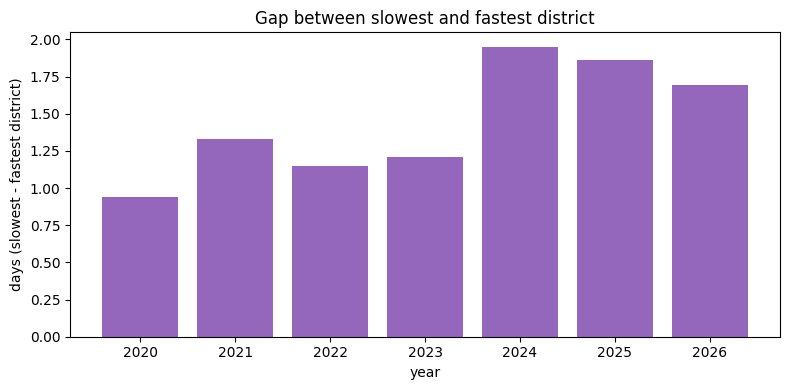

In [48]:
# the gap is the slowest district median minus the fastest district median, every year
# if the gap shrinks over time, service is geting more equal
gap = pd.DataFrame({
    "slowest": medTable.idxmax(),
    "slowestDays": medTable.max(),
    "fastest": medTable.idxmin(),
    "fastestDays": medTable.min()})
gap["gapDays"] = (gap["slowestDays"] - gap["fastestDays"]).round(2)
print(gap)

plt.figure(figsize=(8, 4))
plt.bar(gap.index.astype(str), gap["gapDays"], color="tab:purple")
plt.xlabel("year")
plt.ylabel("days (slowest - fastest district)")
plt.title("Gap between slowest and fastest district")
plt.tight_layout()
plt.show()

In [49]:
# reuse the same mapper, shuffle and reducer but the key is the district and before or after the switch
# so the old and new system are compared directly instead of reading it as one smooth trend
period = mrDf["afterSwitch"].map({True: "after May 2024", False: "before May 2024"})
periodRows = list(zip(mrDf["Council District"], period, mrDf["resolutionDays"]))

periodMapped = []
for c in splitIntoChunks(periodRows, 4):
    periodMapped.append(mapper(c))

periodGrouped = shuffle(periodMapped)

periodReduced = []
for key in periodGrouped:
    periodReduced.append(reducer(key, periodGrouped[key]))

periodTable = pd.DataFrame(periodReduced, columns=["district", "period", "medianDays", "count"])
periodTable = periodTable.pivot(index="district", columns="period", values="medianDays").round(2)
periodTable = periodTable[["before May 2024", "after May 2024"]]
periodTable["change"] = (periodTable["after May 2024"] - periodTable["before May 2024"]).round(2)
print("gap before:", round(periodTable["before May 2024"].max() - periodTable["before May 2024"].min(), 2),
      " gap after:", round(periodTable["after May 2024"].max() - periodTable["after May 2024"].min(), 2))
periodTable.sort_values("change")

gap before: 0.71  gap after: 1.92


period,before May 2024,after May 2024,change
district,,,
NIAGARA,3.77,3.20,-0.57
MASTEN,4.12,3.79,-0.33
ELLICOTT,3.87,3.87,0.00
SOUTH,4.05,4.39,0.34
FILLMORE,3.69,4.22,0.53
UNIVERSITY,4.40,5.12,0.72
LOVEJOY,3.96,4.87,0.91
NORTH,4.01,4.93,0.92
DELAWARE,3.70,4.77,1.07


### MapReduce Write-up
- **Why we chose it:** Q1 and Q3 need the median wait for every district every year, over 514k rows. that fits map (each row emits ((district, year), days)) -> shuffle (group by key) -> reduce (median) really well. medians cant be pre-combined like sums can, so the reducer needs every value for its key, which is exactly what the shuffle gives it
- **Tuning / training:** no training, its an agregation. split the rows into 4 chunks like 4 machines, used median not mean bc of the outliers, then reused the same mapper / shuffle / reducer w a diff key (before vs after May 2024)
- **Metrics:** output matches pandas groupby exactly (63 district x year keys) and runs in aprox 0.2 sec. % of requests still open: 5.8% for 2024 and 8.4% for 2026, so those years medians r probly a bit to low
- **What it tells us:** the gap between the slowest and fastest district went from aprox 1 day in 2020 to 1.95 in 2024 and 1.7 in 2026. before the switch the gap was 0.71 days, after its 1.92, and UNIVERSITY was the slowest every year 2022-2025. so the gaps got worse, not better. but the new system might record "closed" diffrently, and recent years still have open cases, so we cant say for sure its all service getting worse